# -- Setup --

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Chart style: white background,

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#E69F00", "#009E73", "#D55E00",
                                         "#CC79A7", "#56B4E9", "#F0E442", "#000000"]),
    "axes.edgecolor": "#555555",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e5e5e5",
    "text.color": "#222222",
    "axes.labelcolor": "#333333",
    "xtick.color": "#555555",
    "ytick.color": "#555555",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "legend.frameon": False,
})

# -- Load --

## What's in the raw file?

In [3]:
df = pd.read_csv("Books_Data_Clean.csv")

In [4]:
df.head()

,index,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
0,0,1975.0,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.42,155903,genre fiction,34160.0,20496.0,4.88,1,HarperCollins Publishers,7000
1,1,1987.0,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lew...",eng,Intermediate,4.23,145267,genre fiction,12437.5,7462.5,1.99,2,HarperCollins Publishers,6250
2,2,2015.0,Go Set a Watchman,Harper Lee,eng,Novice,3.31,138669,genre fiction,47795.0,28677.0,8.69,3,"Amazon Digital Services, Inc.",5500
3,3,2008.0,When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.04,150898,fiction,41250.0,24750.0,7.50,3,Hachette Book Group,5500
4,4,2011.0,Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.04,198283,genre fiction,37952.5,22771.5,7.99,4,Penguin Group (USA) LLC,4750


## After loading the data there are 1,070 rows and 15 columns

# -- Inspecting raw data --

## What's wrong before cleaning?

In [5]:
df.describe()

,index,Publishing Year,Book_average_rating,Book_ratings_count,gross sales,publisher revenue,sale price,sales rank,units sold
count,1070.000000,1069.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000
mean,534.500000,1971.377923,4.007000,94909.913084,1856.622944,843.281030,4.869561,611.652336,9676.980374
std,309.026698,185.080257,0.247244,31513.242518,3936.924240,2257.596743,3.559919,369.849830,15370.571306
min,0.000000,-560.000000,2.970000,27308.000000,104.940000,0.000000,0.990000,1.000000,106.000000
25%,267.250000,1985.000000,3.850000,70398.000000,372.465000,0.000000,1.990000,287.500000,551.250000
50%,534.500000,2003.000000,4.015000,89309.000000,809.745000,273.078000,3.990000,595.500000,3924.000000
75%,801.750000,2010.000000,4.170000,113906.500000,1487.957500,721.180500,6.990000,932.500000,5312.250000
max,1069.000000,2016.000000,4.770000,206792.000000,47795.000000,28677.000000,33.860000,1273.000000,61560.000000


In [6]:
print(df.isna().sum())

index                   0
Publishing Year         1
Book Name              23
Author                  0
language_code          53
Author_Rating           0
Book_average_rating     0
Book_ratings_count      0
genre                   0
gross sales             0
publisher revenue       0
sale price              0
sales rank              0
Publisher               0
units sold              0
dtype: int64


In [7]:
df.nunique()

index                  1070
Publishing Year         150
Book Name              1045
Author                  735
language_code             8
Author_Rating             4
Book_average_rating     134
Book_ratings_count     1064
genre                     4
gross sales             831
publisher revenue       610
sale price              149
sales rank              865
Publisher                 9
units sold              491
dtype: int64

## 23 missing titles, 53 missing languages, years down to -560, publisher name has different variants

# -- Clean rows --

## Which rows are in scope?

In [8]:
# 1. Scope: works first published after 1900
before = len(df)
df = df[df["Publishing Year"] > 1900]
print(f"Year scope: {before} -> {len(df)}")

Year scope: 1070 -> 1009


In [9]:
# 2. Drop rows with no title (can't be identified or de-duplicated)
before = len(df)
df = df.dropna(subset=["Book Name"])
print(f'Missing titles: {before} -> {len(df)}')

Missing titles: 1009 -> 988


In [10]:
# 3. Check for exact duplicate rows
print('Duplicate rows', df.duplicated().sum())

Duplicate rows 0


## 1070 -> 1009 (scope, post-1900) -> 988 (no title); 0 duplicates

# -- Clean labels --

## Do equal things have equal labels?

In [11]:
# 1. Column names: strip stray spaces so df["Publisher"] works
df.columns = df.columns.str.strip()

In [12]:
# 2. Text columns: strip ends and collapse repeated internal spaces
for col in ["Publisher", "Author", "Book Name"]:
    df[col] = df[col].str.replace(r"\s+"," ", regex=True).str.strip()


In [13]:
# 3. Publisher spelling variants -> one label (HarperCollins Christian will be kept separate - distinct division)
df["Publisher"] = df["Publisher"].replace({
    "HarperCollins Publishing": "HarperCollins Publishers"
})

In [14]:
# 4. Language: analyse at the language level, not regional variant
lang_map = {"eng": "en", "en-US": "en", "en-GB": "en", "en-CA": "en",
            "fre": "fr", "spa": "es", "ara": "ar", "nl": "nl"}

df["language"] = df["language_code"].map(lang_map)


In [15]:
# Author strings include editors/translators; keep the first-listed name.
# Limitation: first name is occasionally a translator or "Unknown".
df["first_author"] = df["Author"].str.split(",").str[0].str.strip()

# Rank by mean rating only among authors with enough books to make sense
k = 3
auth = df.groupby("first_author")["Book_average_rating"].agg(books="count", mean_rating="mean")
auth[auth["books"] >= k].sort_values("mean_rating", ascending = False).head(10)

,books,mean_rating
first_author,,
Sarah J. Maas,5,4.526000
Marissa Meyer,3,4.416667
Brandon Sanderson,6,4.400000
Diana Gabaldon,5,4.366000
Rick Riordan,4,4.357500
J.R. Ward,7,4.334286
Richelle Mead,3,4.333333
Colleen Hoover,6,4.333333
Jennifer L. Armentrout,3,4.300000


 ## 8 publishers after merging; English is 99% of known languages, so language is dropped as a variable

# -- Univariate --

## What does each variable look like?

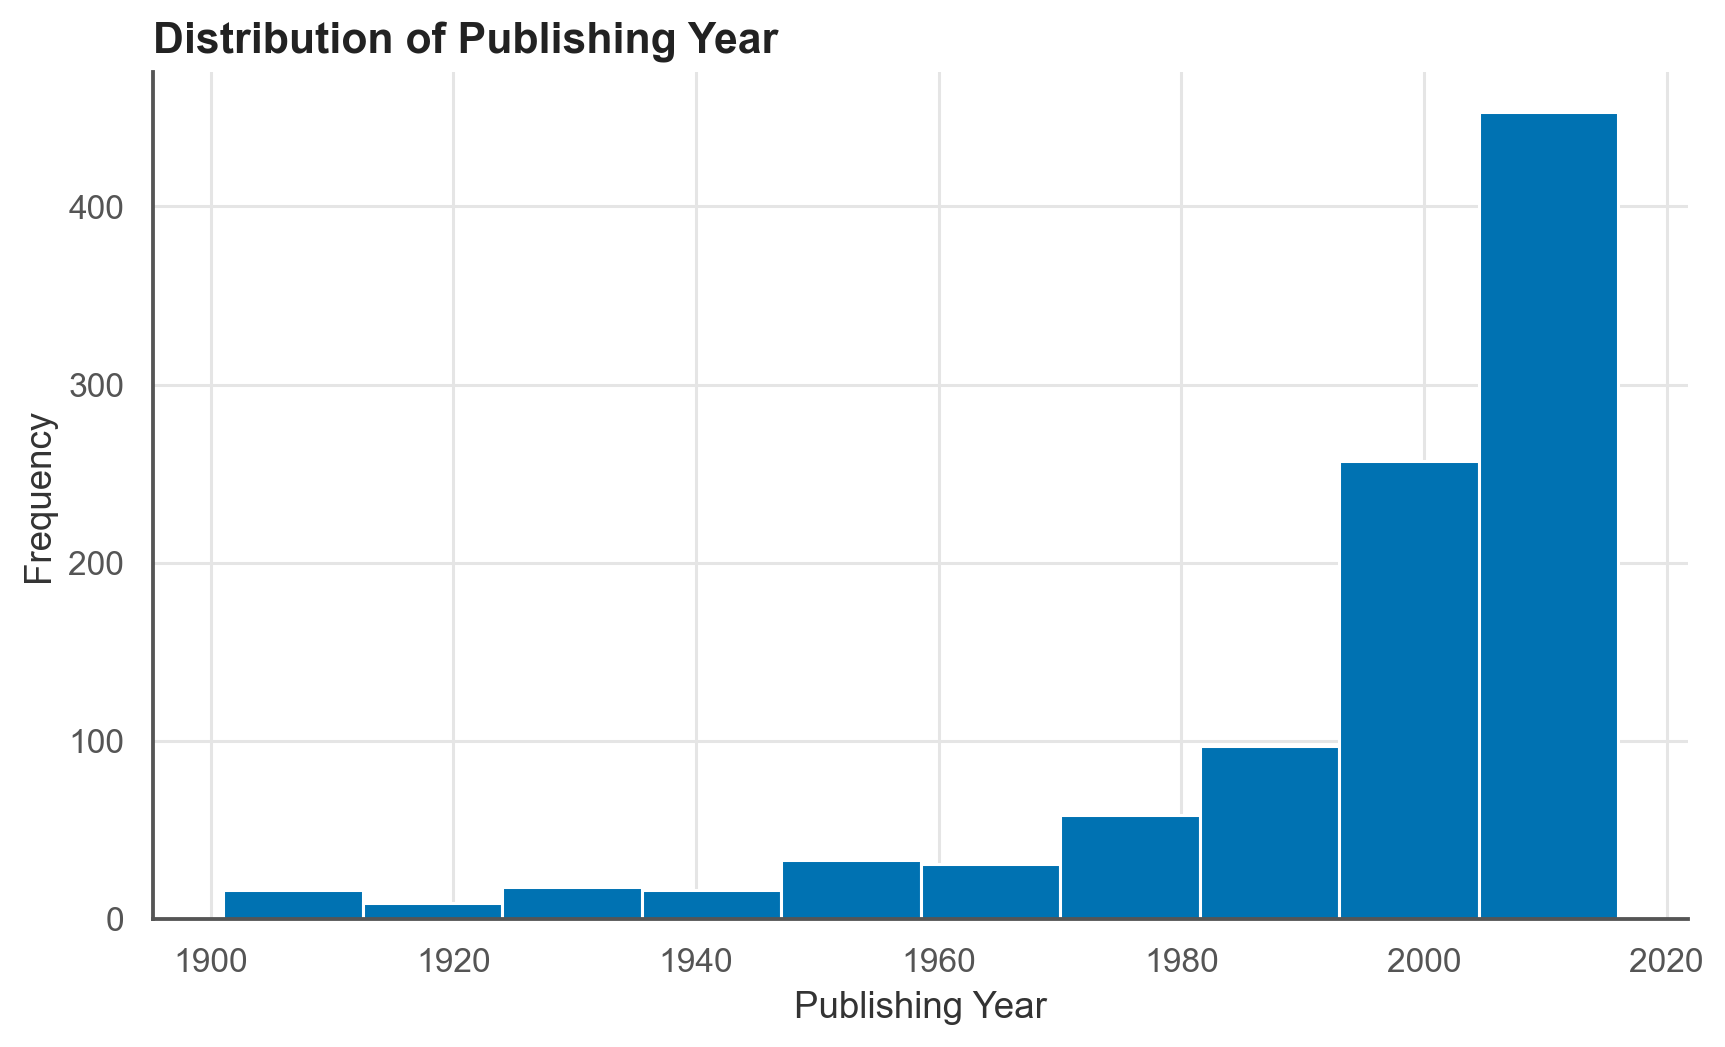

In [16]:
plt.hist(df["Publishing Year"])
plt.xlabel("Publishing Year")
plt.ylabel("Frequency")
plt.title("Distribution of Publishing Year")
plt.show()

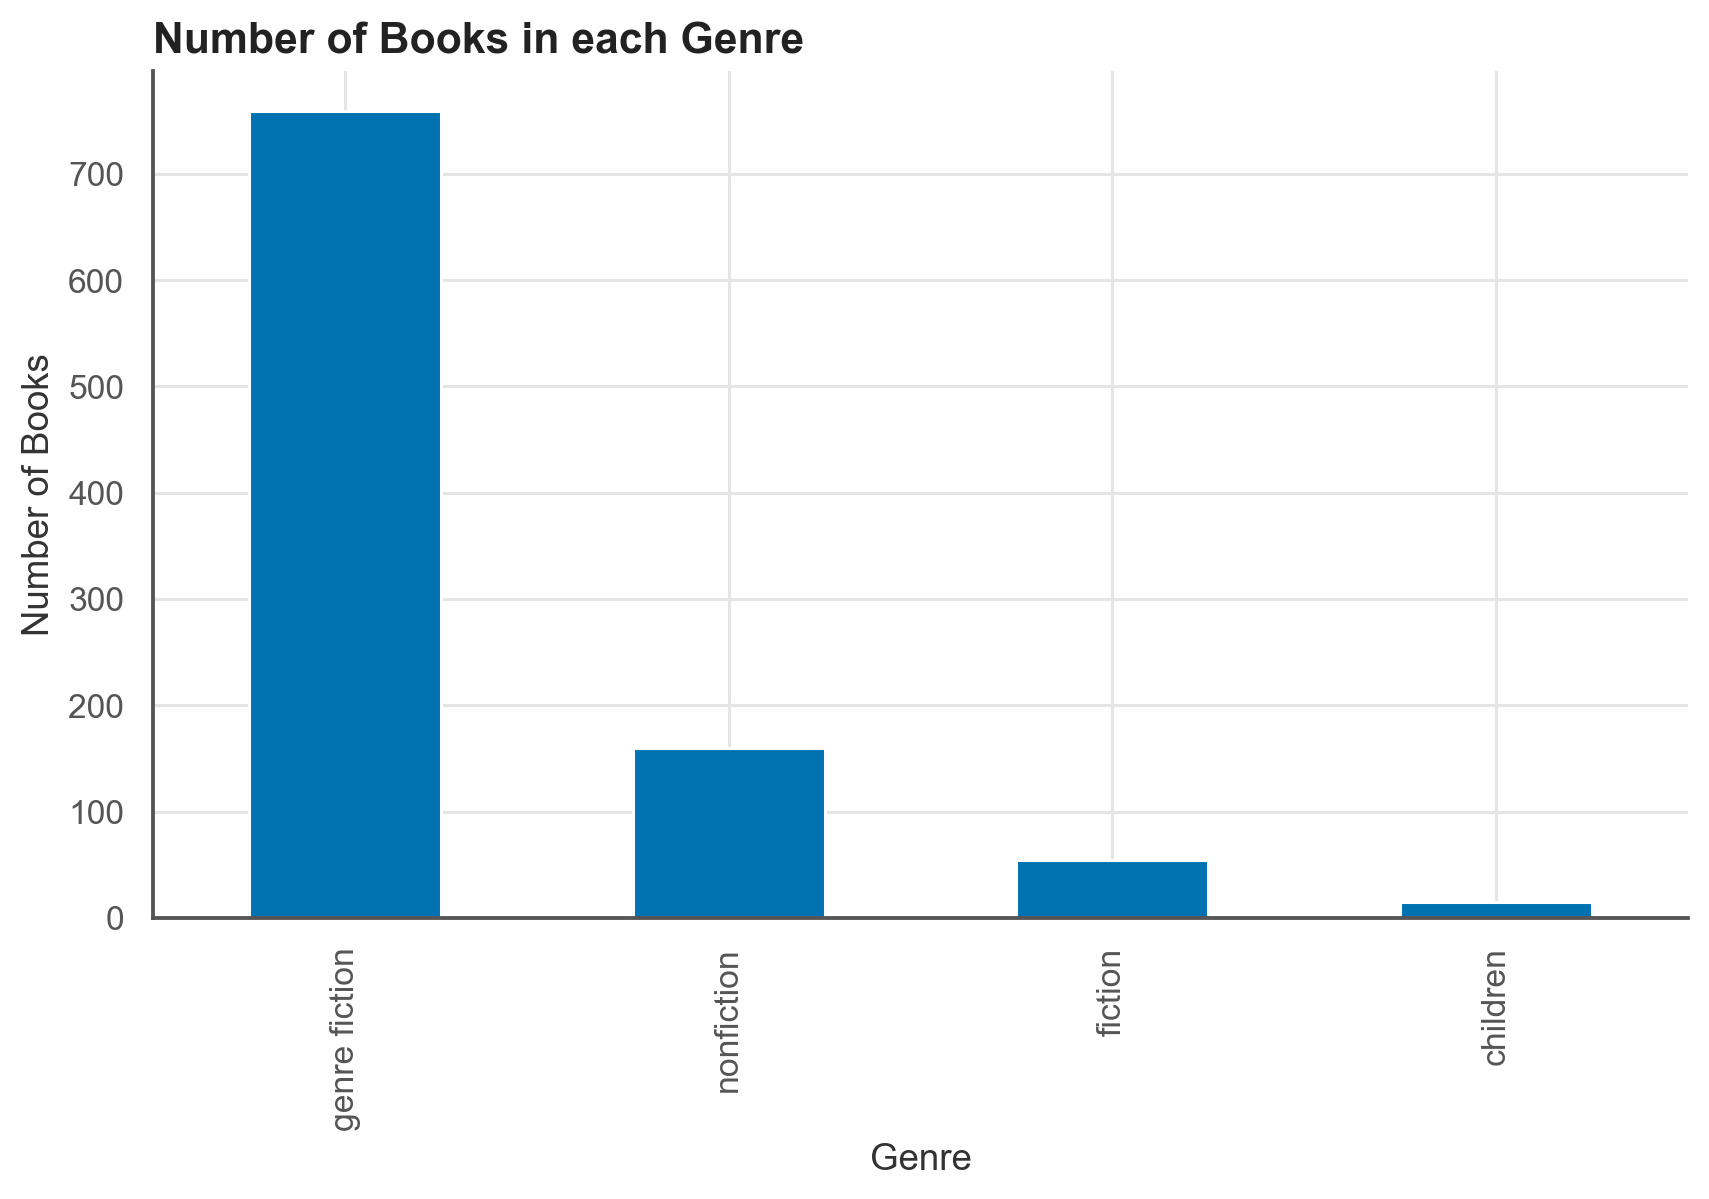

In [17]:
df["genre"].value_counts().plot(kind="bar")
plt.xlabel("Genre")
plt.ylabel("Number of Books")
plt.title("Number of Books in each Genre")
plt.show()

In [18]:
# Language: after merging regional English codes, the variable is ~constant
lang = df["language"].value_counts(dropna = False)
print(lang)
known = df["language"].notna().sum()
print(f"English share of known languages: {lang['en'] / known:.1%}")

language
en     932
NaN     47
fr       4
es       2
ar       2
nl       1
Name: count, dtype: int64
English share of known languages: 99.0%


## units sold is right skewed (mean > Q3) -> medians are reported

# -- Bivariate --

## What relates to sales and ratings?

In [19]:
# Publisher revenue: total = number of books x revenue per book
# Show both factors so a big total isn't mistaken for string per-book performance.
pub = (df.groupby("Publisher")["publisher revenue"]
        .agg(books='count',total ='sum',median_per_book='median',mean_revenue_per_book='mean', share_zero=lambda s:(s == 0).mean())
       .sort_values('total',ascending=False))
pub

,books,total,median_per_book,mean_revenue_per_book,share_zero
Publisher,,,,,
Penguin Group (USA) LLC,93,191581.104,820.116,2060.011871,0.000000
Random House LLC,113,174956.244,725.340,1548.285345,0.000000
"Amazon Digital Services, Inc.",561,141767.772,0.000,252.705476,0.611408
HarperCollins Publishers,67,124600.620,738.144,1859.710746,0.000000
Hachette Book Group,56,107410.968,647.250,1918.053000,0.000000
Simon and Schuster Digital Sales Inc,55,46858.206,595.284,851.967382,0.000000
Macmillan,39,31249.830,503.328,801.277692,0.000000
HarperCollins Christian Publishing,4,2135.670,415.716,533.917500,0.000000


In [20]:
df.groupby("Author_Rating")["Book_ratings_count"].agg(["mean","median", "std","count"])

,mean,median,std,count
Author_Rating,,,,
Excellent,83804.800595,81609.5,21023.456069,336
Famous,98295.250000,90527.0,35036.475144,48
Intermediate,101400.272569,98254.5,34210.096082,576
Novice,87318.464286,77446.5,30859.612389,28


In [21]:
print(df[["Book_average_rating","Book_ratings_count"]].corr(method="spearman"))

                     Book_average_rating  Book_ratings_count
Book_average_rating             1.000000            0.114288
Book_ratings_count              0.114288            1.000000


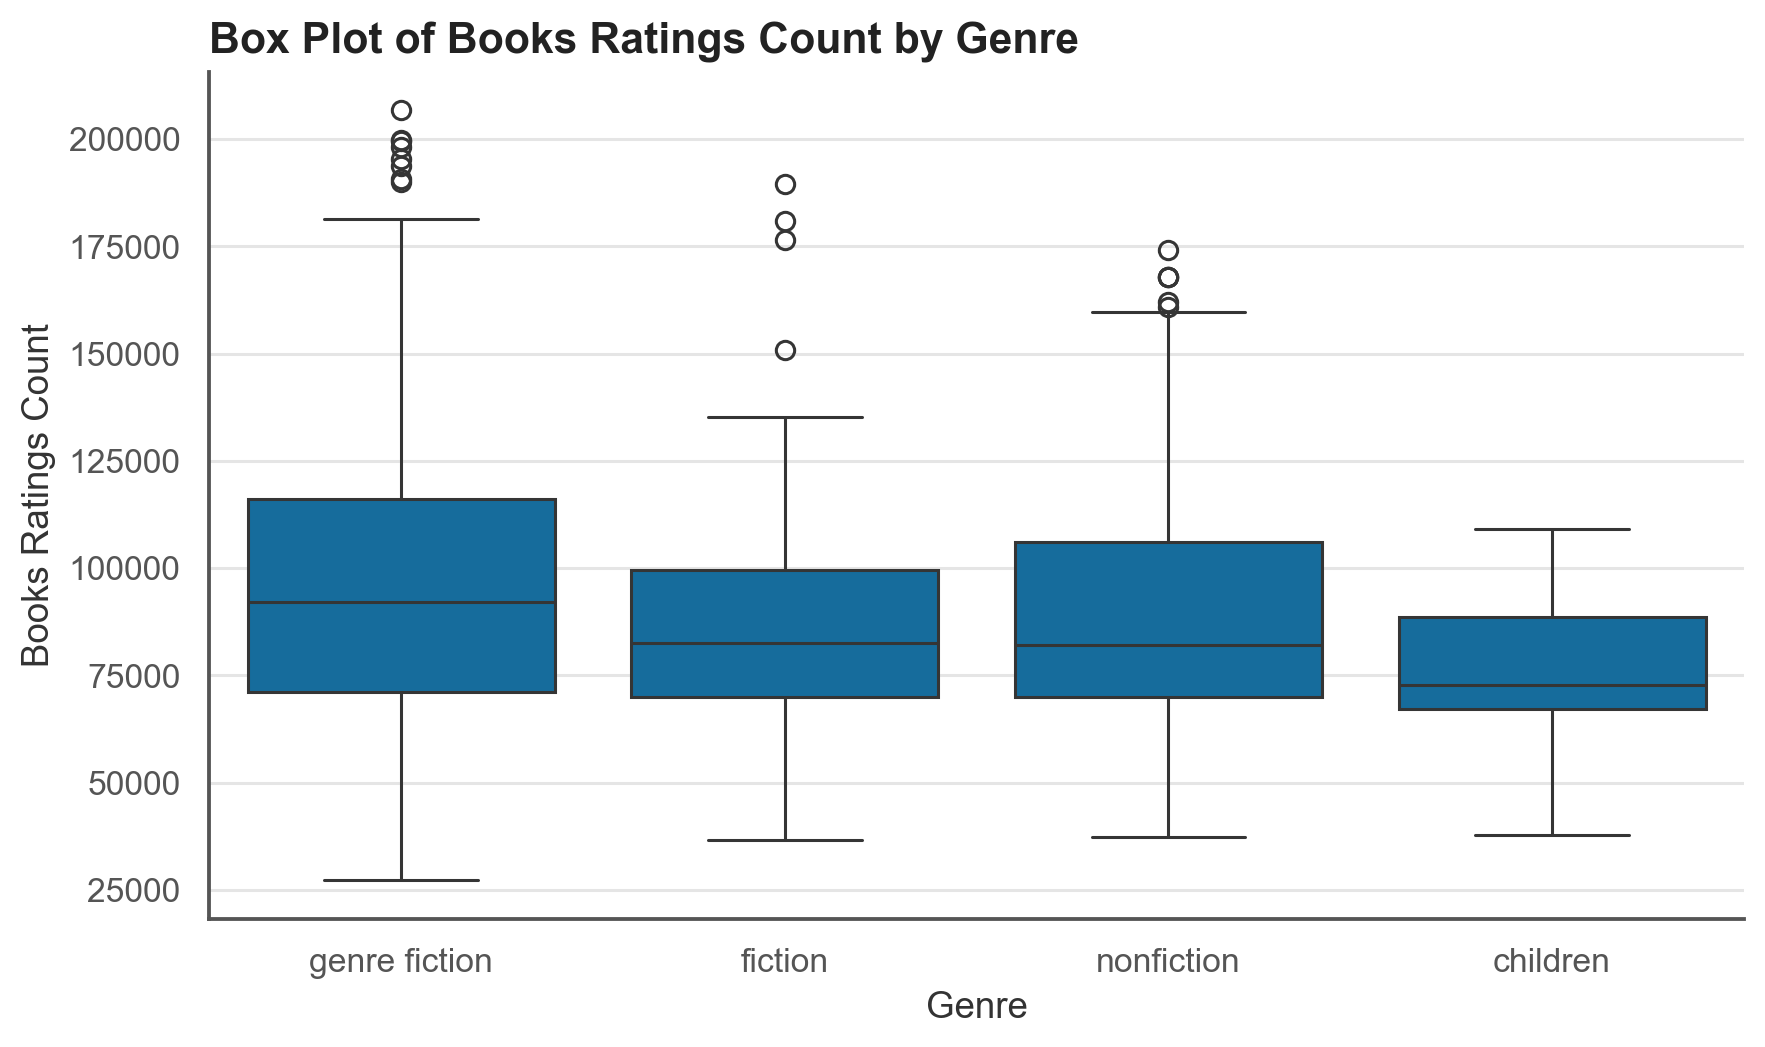

In [22]:
sns.boxplot(x = "genre", y = "Book_ratings_count", data = df)
plt.xlabel("Genre")
plt.ylabel("Books Ratings Count")
plt.title("Box Plot of Books Ratings Count by Genre")
plt.show()

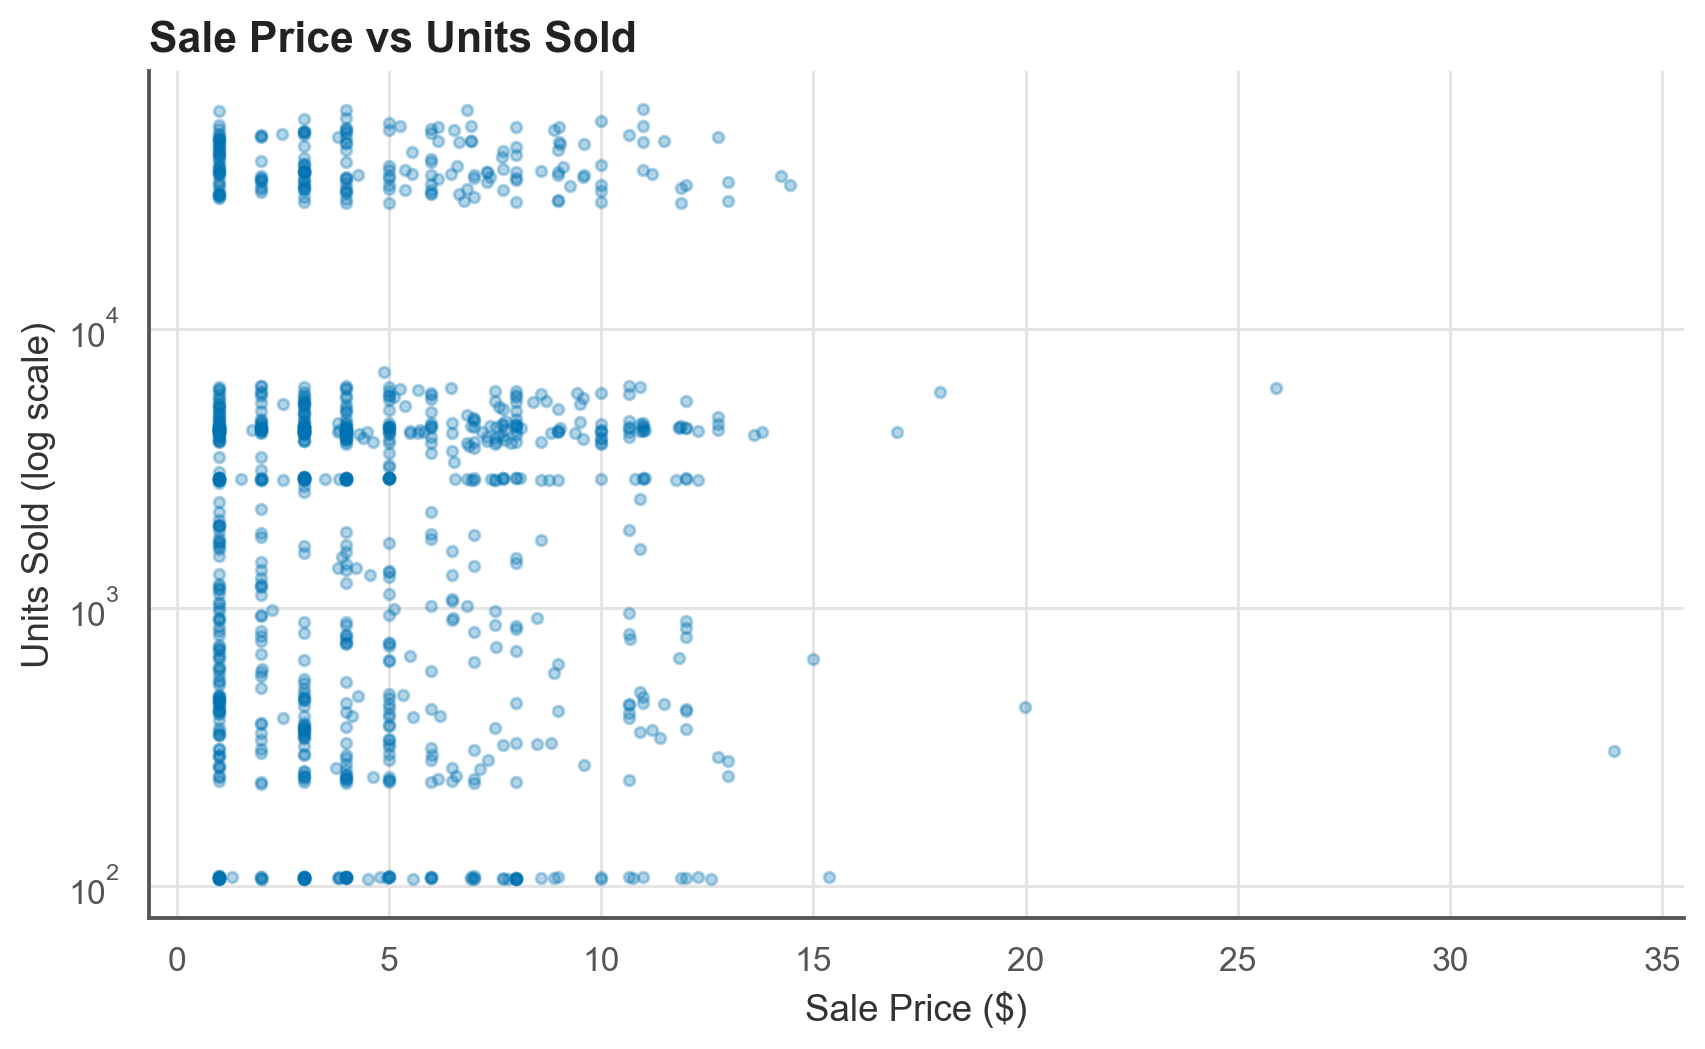

In [23]:
# Prices cluster at a few values (0.99, 1.99, etc) and units sold is right-skewed:
# log y-axis spreads out the skew, alpha shows where points stack up.

plt.scatter(df["sale price"], df["units sold"], alpha = 0.3, s=12)
plt.yscale("log")
plt.xlabel("Sale Price ($)")
plt.ylabel("Units Sold (log scale)")
plt.title("Sale Price vs Units Sold")
plt.show()


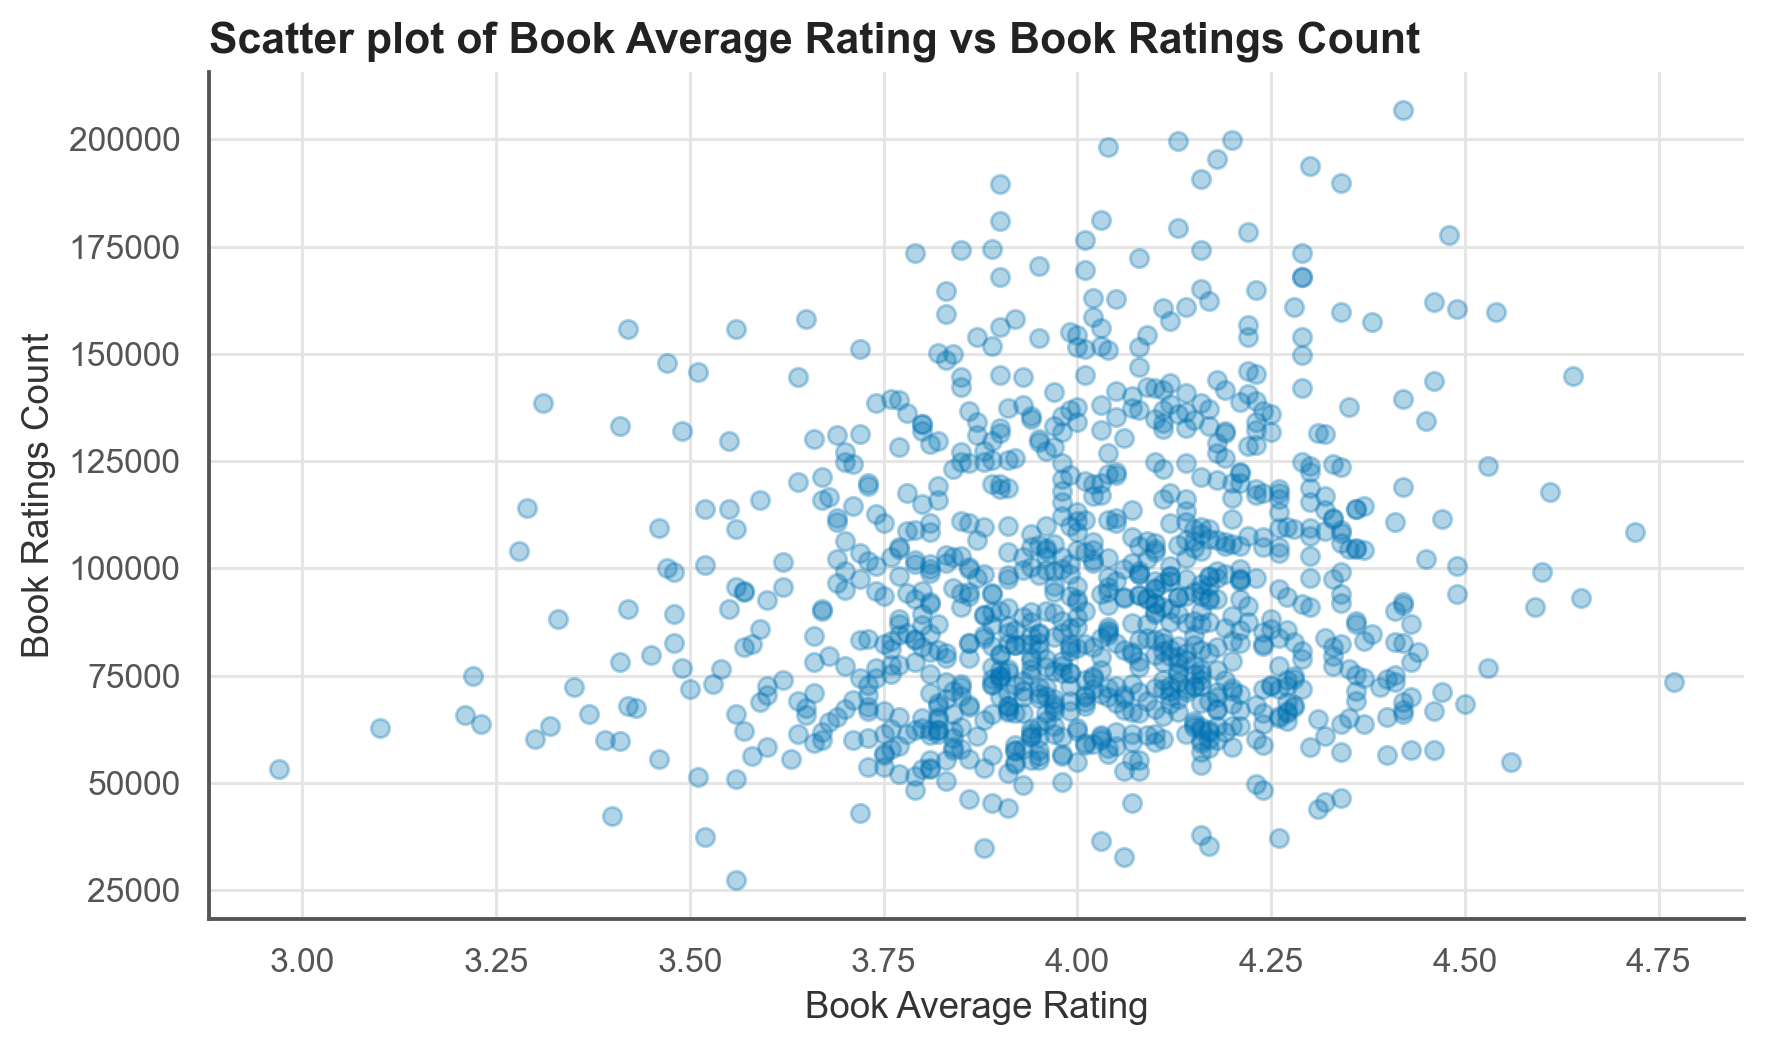

In [24]:
plt.scatter(df["Book_average_rating"], df["Book_ratings_count"], alpha = 0.3)
plt.xlabel("Book Average Rating")
plt.ylabel("Book Ratings Count")
plt.title("Scatter plot of Book Average Rating vs Book Ratings Count")
plt.show()

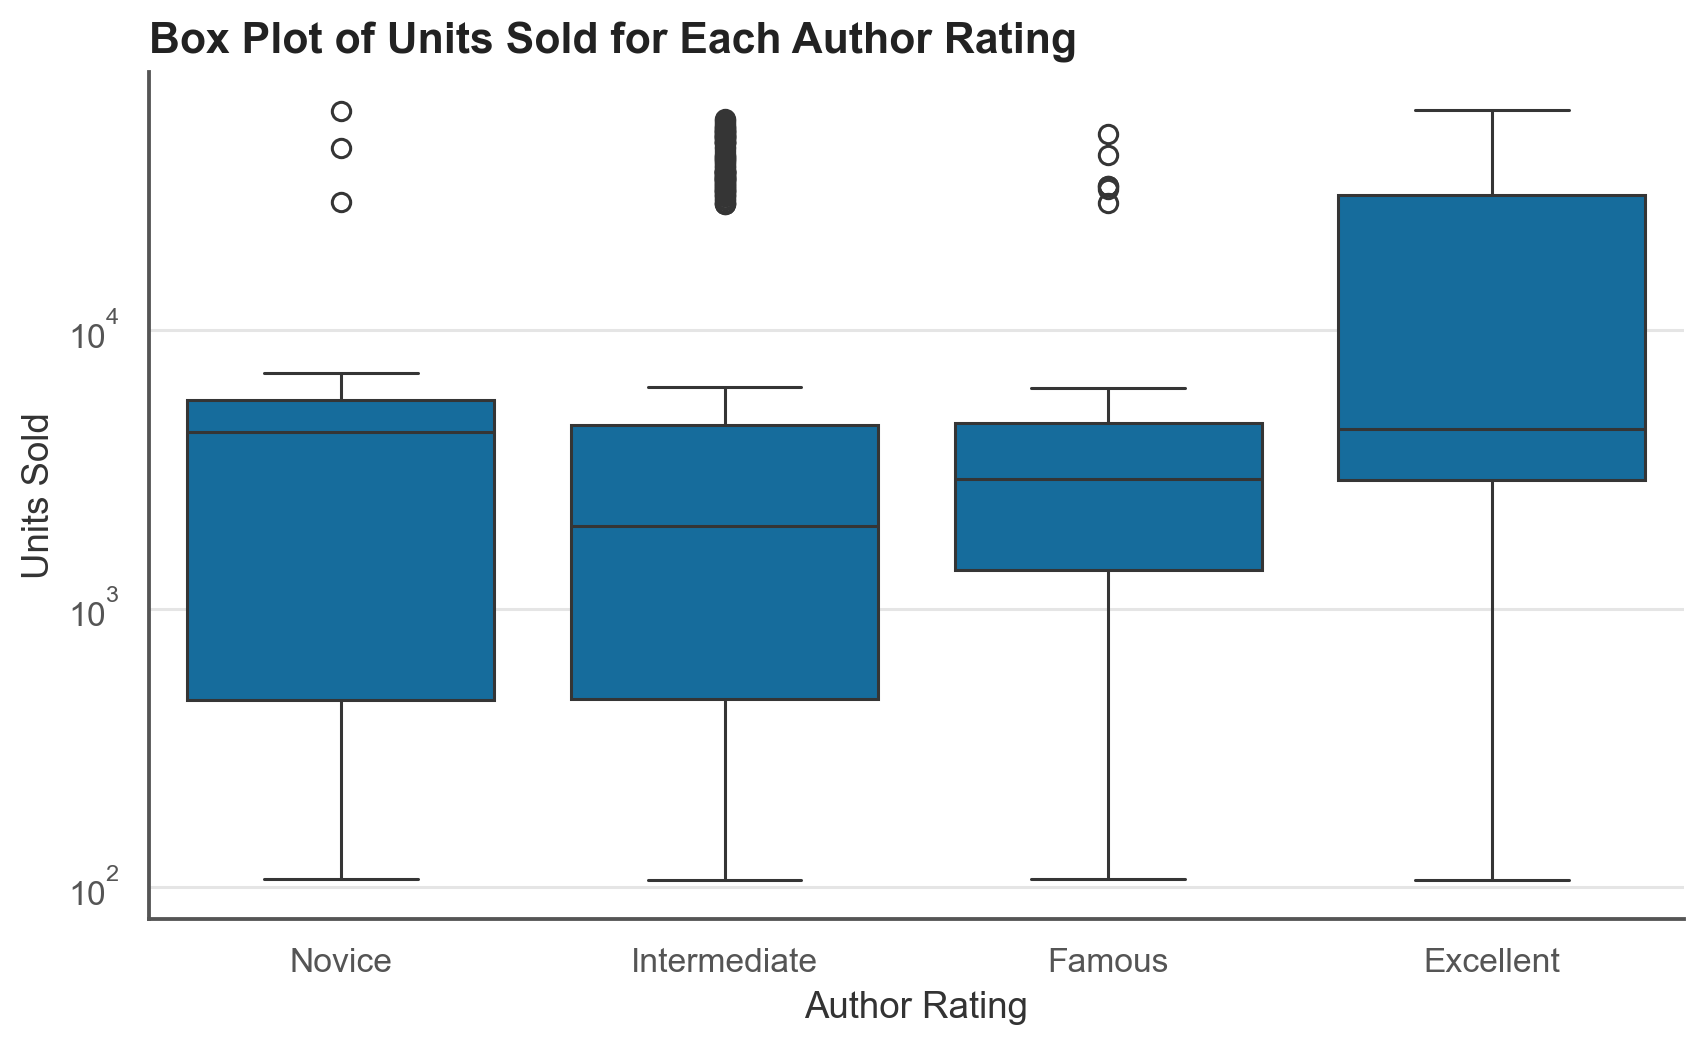

In [25]:
sns.boxplot(x = "Author_Rating", y = "units sold", data = df)
plt.xlabel("Author Rating")
plt.yscale("log")
plt.ylabel("Units Sold")
plt.title("Box Plot of Units Sold for Each Author Rating")
plt.show()

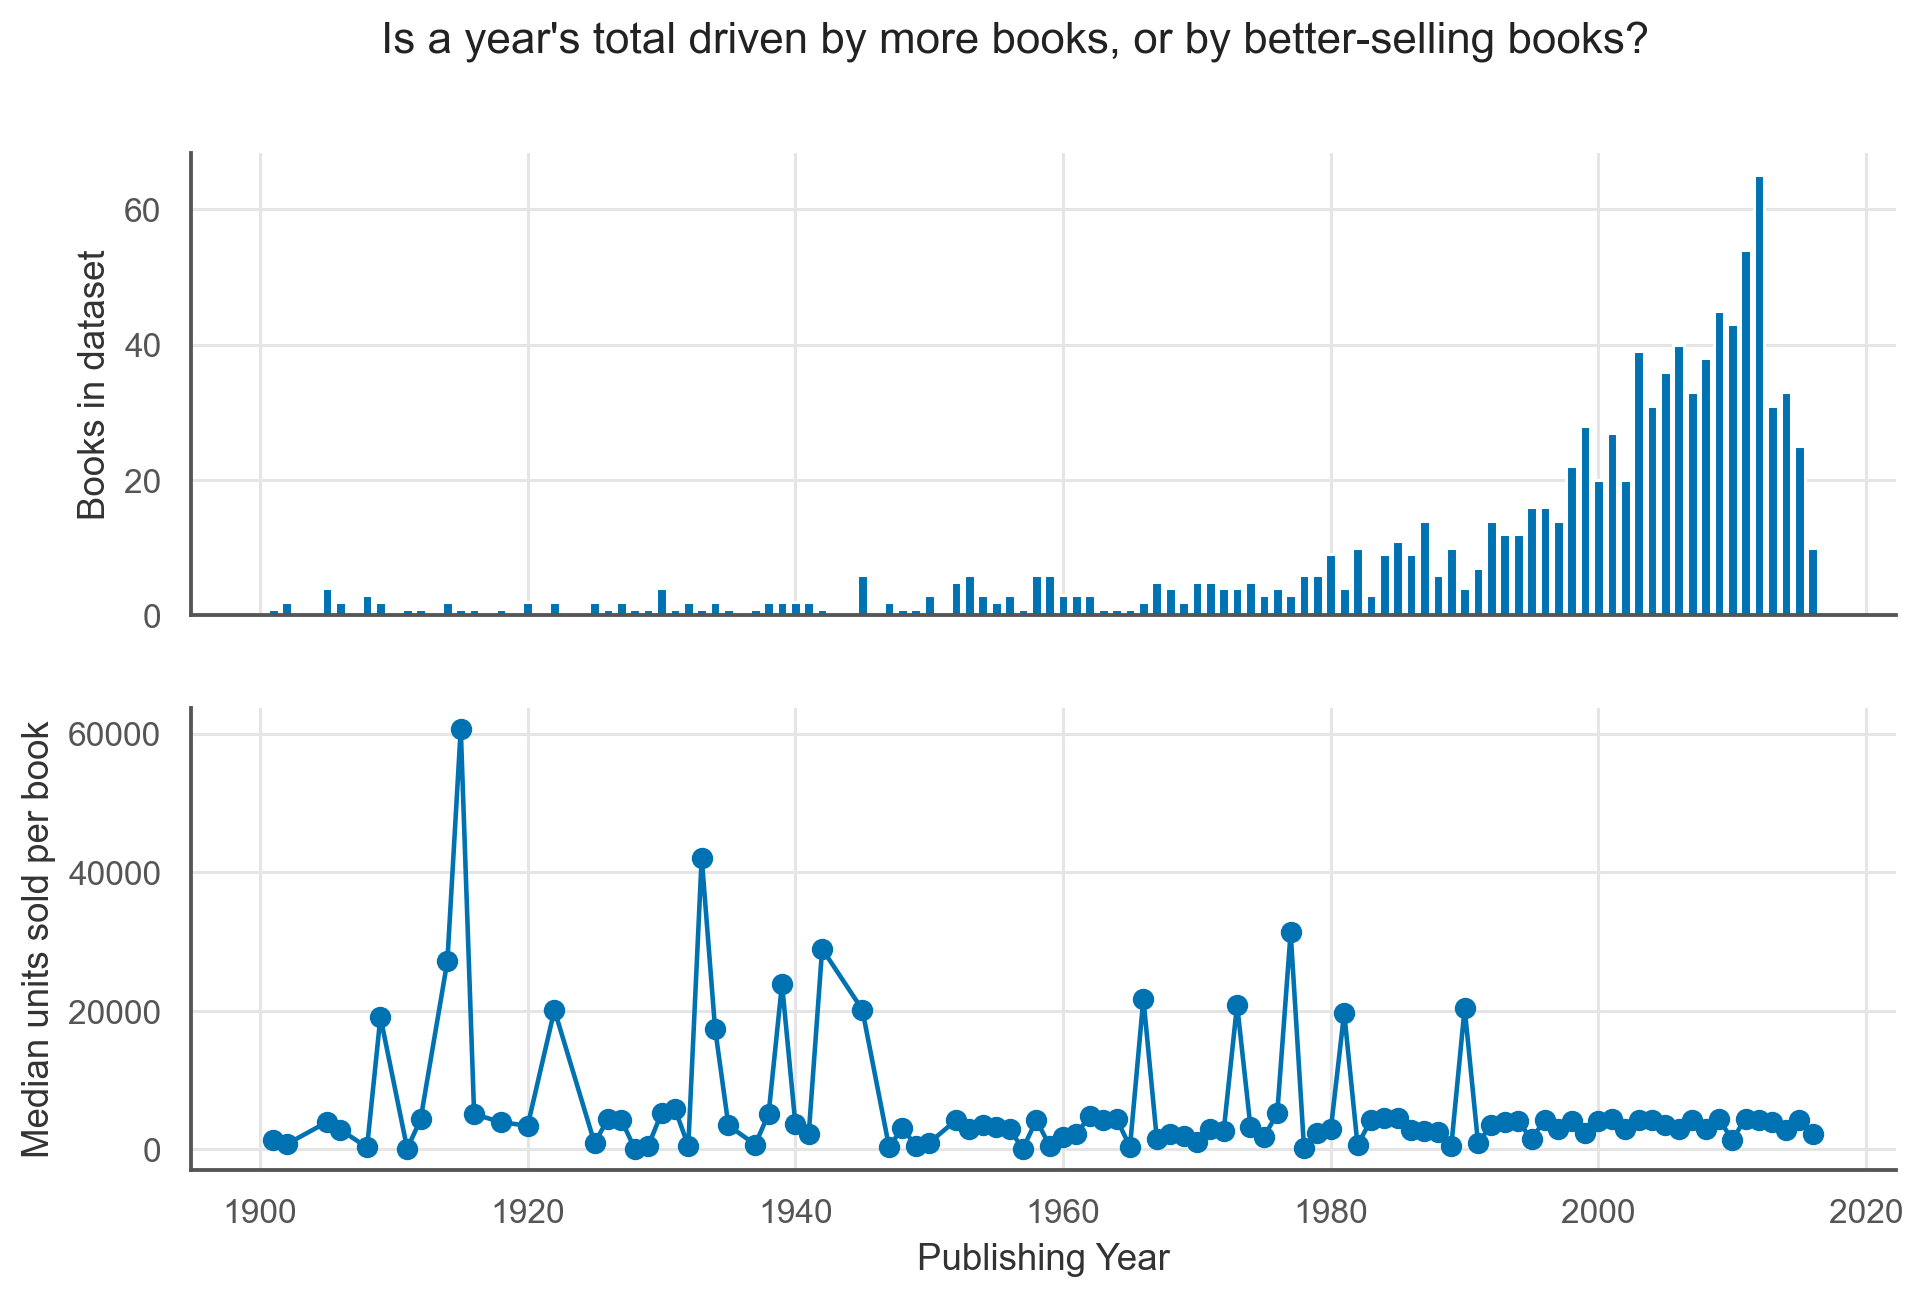

In [26]:
# Units sold by publishing year, split into its two factors:
# total = (number of books) x (units per book)
by_year = df.groupby("Publishing Year")["units sold"].agg(["size", "median", "sum"])

fig, axes = plt.subplots(2,1, figsize = (10,6), sharex = True)
axes[0].bar(by_year.index, by_year["size"])
axes[0].set_ylabel("Books in dataset")
axes[1].plot(by_year.index, by_year["median"], marker = "o")
axes[1].set_ylabel("Median units sold per book")
axes[1].set_xlabel("Publishing Year")
fig.suptitle("Is a year's total driven by more books, or by better-selling books?")
plt.show()

| Book Count drives the 2005–2012 peak; median flat; |

## Penguin earns about $2,060 per book vs Amazon $253, driven by Amazon's 61% zeros; rating vs ratings count Spearman p = 0.11(weak)